# Lab 3: Bottom-Up Steel Emissions with Uncertainty


---

## What this lab is

* **Part A: emissions pipeline.** Same tasks, same order, same variable names as Lab 3: operating plants 2020-2030, China utilisation by technology, plant-level production, emission factors, company emissions, projection to 2030.
* **Part B : uncertainty quantification.** You will *interrogate* your own Lab 3 numbers with the tools of the Session 4 lecture: where do the numbers come from, how sure can we be, and what would a risk committee need to know?


## Learning goals

1. Rebuild a bottom-up emissions pipeline from plant-level data (Lab 3).
2. Tell **aleatoric, epistemic and scenario** uncertainty apart.
3. Spot a **data-coverage problem** by checking against official statistics.
4. Give a **range instead of a single number** (bootstrap and simulation) and find which input matters most.
5. Compare **scenarios** and communicate the result with calibrated words.

## Conventions

* Questions are **[QUAL]** (2-4 sentences) or **[QUANT]** (a number from your code plus one sentence).
* Write each answer in the cell right under the question.
* `ttpa` = thousand tonnes per annum. Emissions in Part A are in tCO2; in Part B we switch to **MtCO2**.
* Boxes marked **[OPTIONAL]** can be skipped.
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in **groups of up to 4**. Fill in every member before submitting.

1. Full name: Edouard Souied  Student ID: B00825107
2. Full name: Josh Soussan  Student ID: B0082791
3. Full name: Nicolas Salapete  Student ID: B00821820
4. Full name: _______________  Student ID: _______________

**Group / repo name:** `aidams-lab3-<surname1>-<surname2>-...`  
**Submitter (one person):**  
**Repo URL:**  

### What to submit

- This notebook (`lab3.ipynb`) with all tasks completed and cells run (outputs visible)
- A short `README.md` with how to run the notebook

Create a GitHub repo, push the notebook and README, invite the instructor, and paste the **repo URL** above.

**Send submission info to my email (1 email per group).** Include the GitHub repo URL.

**Done when:** all names are filled in and the notebook contains outputs (no need for the instructor to re-run it).


## Setup (given)

**Note on the data file (added).** The September 2025 V1 workbook named in the setup cell is no longer distributed by Global Energy Monitor, so this notebook uses the **June 2026 V1** release of the same plant-level file (*Global Energy Monitor, Global Iron and Steel Tracker, June 2026 (V1) release*, CC BY 4.0). It has the same three sheets. Three columns were renamed (`GEM plant ID`, `Country/area`, `Parent (English)`); the cell after the setup maps them back to the names used in this lab. Our numbers therefore differ from the figures quoted in the questions (for example the 57% → 8% in Q5), which come from the September 2025 release.

In [1]:
# GEM no longer serves the September 2025 V1 workbook named in the setup cell below, so this
# notebook runs on the June 2026 V1 release of the same file. Set GIST_PATH to use another file.
import os
if "GIST_PATH" not in os.environ:
    os.environ["GIST_PATH"] = "Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx"

In [2]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path(os.environ.get("GIST_PATH", "Plant-level-data-Global-Iron-and-Steel-Tracker-September-2025-V1.xlsx"))
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")

plant_data = pd.read_excel(DATA_PATH, sheet_name="Plant data")
capacity_data = pd.read_excel(DATA_PATH, sheet_name="Plant capacities and status")
production_data = pd.read_excel(DATA_PATH, sheet_name="Plant production")

years = list(range(2020, 2031))
SEED = 42
print(plant_data.shape, capacity_data.shape, production_data.shape)

(1293, 44) (1845, 16) (1393, 10)


In [3]:
# The June 2026 release renamed a few columns: map them back to the names used in this lab.
COLUMN_RENAMES = {"GEM plant ID": "Plant ID", "Country/area": "Country/Area", "Parent (English)": "Parent"}
for df in (plant_data, capacity_data, production_data):
    df.rename(columns=COLUMN_RENAMES, inplace=True)

CAP = "Nominal crude steel capacity (ttpa)"
TECHS = ["BF-BOF", "EAF", "Other"]
OPERATING_STATUSES = ["operating", "operating pre-retirement"]
print("Data file:", DATA_PATH.name)

Data file: Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx


# PART A. Emissions pipeline

## A1. Operating plants 2020-2030

**Goal.** Create `operational_plants`: one row per (plant, year) for the years in `years`, with the plant's `Country/Area`, `Status` and nominal crude steel capacity.
A plant operates in year *t* if `start year <= t <= retired year`. **Assumption (Lab 3):** a missing end date means the plant continues operating.

In [4]:
def to_year(value):
    """GEM date cells mix years (2003), dates (2026-12-01) and text ('unknown'): return the year or NaN."""
    if hasattr(value, "year"):
        return value.year
    return pd.to_numeric(str(value).strip()[:4], errors="coerce")

# A plant can have several capacity records (e.g. an operating line, a retired line, an announced
# expansion). Each record has its own Status and start date; the retirement date is plant-level.
units = capacity_data[["Plant ID", "Status", "Start date", CAP]].copy()
units["Start year"] = units["Start date"].map(to_year)
units[CAP] = pd.to_numeric(units[CAP], errors="coerce")  # ">0" (size unknown) -> NaN
plant_info = plant_data[["Plant ID", "Plant name (English)", "Country/Area"]].assign(
    **{"Retired year": plant_data["Retired date"].map(to_year)})
units = units.merge(plant_info, on="Plant ID", how="left", validate="many_to_one")

# Lab 3 rule: operating in year t if start year <= t <= retired year; a missing end date means still operating.
unit_years = units.merge(pd.DataFrame({"Year": years}), how="cross")
unit_years = unit_years[(unit_years["Start year"] <= unit_years["Year"])
                        & (unit_years["Retired year"].isna() | (unit_years["Year"] <= unit_years["Retired year"]))].copy()
unit_years["Non-operating capacity (ttpa)"] = unit_years[CAP].where(~unit_years["Status"].isin(OPERATING_STATUSES), 0)

# One row per (plant, year): capacity summed over the counted records, their statuses listed.
operational_plants = unit_years.groupby(["Plant ID", "Year"], as_index=False).agg(**{
    "Plant name (English)": ("Plant name (English)", "first"),
    "Country/Area": ("Country/Area", "first"),
    "Status": ("Status", lambda s: "; ".join(sorted(s.unique()))),
    CAP: (CAP, "sum"),
    "Non-operating capacity (ttpa)": ("Non-operating capacity (ttpa)", "sum"),
})
assert not operational_plants.duplicated(["Plant ID", "Year"]).any()

no_start = units[units["Start year"].isna()]
print(f"operational_plants: {len(operational_plants):,} plant-years, {operational_plants['Plant ID'].nunique():,} plants")
print(f"Capacity records never counted (unknown start year): {len(no_start)} ({no_start[CAP].sum():,.0f} ttpa), "
      f"by status: {no_start['Status'].value_counts().to_dict()}")
display(operational_plants.groupby("Year").agg(plants=("Plant ID", "size"), capacity_ttpa=(CAP, "sum")))
display(operational_plants.head())

operational_plants: 11,409 plant-years, 1,163 plants
Capacity records never counted (unknown start year): 284 (437,130 ttpa), by status: {'announced': 161, 'construction': 79, 'cancelled': 25, 'operating': 13, 'retired': 4, 'mothballed': 2}


,plants,capacity_ttpa
Year,,
2020,1021,"2,599,151.00"
2021,1025,"2,597,510.00"
2022,1026,"2,588,617.00"
2023,1019,"2,565,507.00"
2024,1013,"2,553,832.00"
2025,1019,"2,561,552.00"
2026,1028,"2,631,288.00"
2027,1047,"2,718,132.00"
2028,1055,"2,770,813.00"


,Plant ID,Year,Plant name (English),Country/Area,Status,Nominal crude steel capacity (ttpa),Non-operating capacity (ttpa)
0,P100000120001,2020,Emsteel Abu Dhabi steel plant,United Arab Emirates,operating,"3,500.00",0.00
1,P100000120001,2021,Emsteel Abu Dhabi steel plant,United Arab Emirates,operating,"3,500.00",0.00
2,P100000120001,2022,Emsteel Abu Dhabi steel plant,United Arab Emirates,operating,"3,500.00",0.00
3,P100000120001,2023,Emsteel Abu Dhabi steel plant,United Arab Emirates,operating,"3,500.00",0.00
4,P100000120001,2024,Emsteel Abu Dhabi steel plant,United Arab Emirates,operating,"3,500.00",0.00


### Q1 [QUANT] Is every "operating" plant really operating?

Using your `operational_plants` for **China**: for the years **2020 and 2026**, how many plants and how much capacity (ttpa) are counted as operating although their **`Status`** is not an operating status (look at the values of `Status` first)?
Give the share of the Chinese total.

In [5]:
print("Status values (one per capacity record):", capacity_data["Status"].value_counts().to_dict(), "\n")

china_op = operational_plants[operational_plants["Country/Area"] == "China"]
status_sets = china_op["Status"].str.split("; ").map(set)
has_non_op = status_sets.map(lambda s: bool(s - set(OPERATING_STATUSES)))  # at least one non-operating record
no_op = status_sets.map(lambda s: not (s & set(OPERATING_STATUSES)))       # no operating record at all

for year in [2020, 2026]:
    in_year = china_op["Year"] == year
    n_plants, cap_total = in_year.sum(), china_op.loc[in_year, CAP].sum()
    n_non_op, n_no_op = (in_year & has_non_op).sum(), (in_year & no_op).sum()
    cap_non_op = china_op.loc[in_year, "Non-operating capacity (ttpa)"].sum()
    print(f"{year}: {n_plants} Chinese plants counted as operating, {cap_total:,.0f} ttpa")
    print(f"   plants with a non-operating status: {n_non_op} ({n_non_op / n_plants:.1%}), "
          f"of which {n_no_op} ({n_no_op / n_plants:.1%} of all) have no operating record at all")
    print(f"   capacity with a non-operating status: {cap_non_op:,.0f} ttpa ({cap_non_op / cap_total:.1%} of the total)")

china_non_op_units = unit_years[(unit_years["Country/Area"] == "China") & unit_years["Year"].isin([2020, 2026])
                                & ~unit_years["Status"].isin(OPERATING_STATUSES)]
print("\nNon-operating capacity counted as operating, by status (ttpa):")
display(china_non_op_units.pivot_table(index="Status", columns="Year", values=CAP, aggfunc="sum", fill_value=0))

Status values (one per capacity record): {'operating': 935, 'announced': 287, 'retired': 232, 'construction': 140, 'operating pre-retirement': 97, 'cancelled': 76, 'mothballed': 72, 'mothballed pre-retirement': 6} 

2020: 411 Chinese plants counted as operating, 1,339,037 ttpa
   plants with a non-operating status: 185 (45.0%), of which 70 (17.0% of all) have no operating record at all
   capacity with a non-operating status: 315,747 ttpa (23.6% of the total)
2026: 375 Chinese plants counted as operating, 1,279,207 ttpa
   plants with a non-operating status: 130 (34.7%), of which 10 (2.7% of all) have no operating record at all
   capacity with a non-operating status: 192,523 ttpa (15.1% of the total)

Non-operating capacity counted as operating, by status (ttpa):


Year,2020,2026
Status,,
announced,0.00,"5,450.00"
cancelled,"10,903.00","12,453.00"
construction,0.00,"8,053.00"
mothballed,"4,650.00","4,650.00"
mothballed pre-retirement,"3,150.00","3,150.00"
retired,"297,044.00","158,767.00"


**Your answer (Q1):**

"Operating" statuses are `operating` and `operating pre-retirement`. The others are `retired`, `cancelled`, `mothballed`, `mothballed pre-retirement`, `construction` and `announced`. The rule still counts all of them as operating.

* **2020:** **185 of the 411** Chinese plants counted as operating (**45%**) carry at least one non-operating capacity record, and 70 (17% of all) have no operating record at all. That is **315,747 ttpa, or 23.6%** of China's counted capacity (1,339,037 ttpa): 297,044 ttpa retired, 10,903 cancelled and 7,800 mothballed.
* **2026:** **130 of 375** plants (**35%**; 10 with no operating record at all) and **192,523 ttpa, or 15.1%** of 1,279,207 ttpa: 158,767 retired, 12,453 cancelled, 8,053 under construction, 5,450 announced and 7,800 mothballed.

The rule only looks at dates. A retired line keeps counting when its plant has no retirement date (the rest of the plant still runs). Cancelled projects count from their start date, and projects still under construction or only announced count as soon as their planned start year is reached. GEM statuses describe mid-2026, so part of the 2020 "retired" capacity was really still running in 2020 and retired later; by 2026, almost all of the 15% is a counting error.

## A2. China production and capacity

**Goal.** Create
* `crude_steel`: plant-year production (crude steel only), with `Country/Area`, `Owner`, `Parent` and `Main production equipment` attached;
* `china_production`: China total production by year (a Series indexed by year);
* `china_operational`: the rows of `operational_plants` for China;
* `china_capacity`: China total capacity by year.

In [6]:
year_cols = [c for c in production_data.columns if str(c).isdigit()]
crude_steel = (production_data[production_data["Type of production"] == "Crude steel production (ttpa)"]
               .drop_duplicates()  # the sheet repeats some rows verbatim
               .melt(id_vars="Plant ID", value_vars=year_cols, var_name="Year", value_name="Production_ttpa"))
crude_steel["Year"] = crude_steel["Year"].astype(int)
crude_steel["Production_ttpa"] = pd.to_numeric(crude_steel["Production_ttpa"], errors="coerce")  # 'unknown' -> NaN
crude_steel = (crude_steel[crude_steel["Year"].isin(years)].dropna(subset=["Production_ttpa"])
               .groupby(["Plant ID", "Year"], as_index=False)["Production_ttpa"].max())  # one value per plant-year
crude_steel = crude_steel.merge(
    plant_data[["Plant ID", "Country/Area", "Owner", "Parent", "Main production equipment"]],
    on="Plant ID", how="left", validate="many_to_one")

china_crude = crude_steel[crude_steel["Country/Area"] == "China"]
china_production = china_crude.groupby("Year")["Production_ttpa"].sum()
china_operational = operational_plants[operational_plants["Country/Area"] == "China"].copy()
china_capacity = china_operational.groupby("Year")[CAP].sum()

display(pd.DataFrame({"plants reporting": china_crude.groupby("Year").size(),
                      "china_production (ttpa)": china_production,
                      "china_capacity (ttpa)": china_capacity}).astype({"plants reporting": "Int64"}))

,plants reporting,china_production (ttpa),china_capacity (ttpa)
Year,,,
2020,35,"177,048.00","1,339,037.00"
2021,15,"54,817.00","1,336,290.00"
2022,21,"119,752.00","1,321,524.00"
2023,21,"97,068.00","1,288,024.00"
2024,11,"77,204.00","1,279,104.00"
2025,<NA>,NaN,"1,278,504.00"
2026,<NA>,NaN,"1,279,207.00"
2027,<NA>,NaN,"1,278,032.00"
2028,<NA>,NaN,"1,278,032.00"


## A3. Utilisation by technology

**Goal.** Compute the utilisation rate (production / capacity) separately for **BF-BOF** and **EAF** (and a residual class "Other").
Create `classify_technology` (function), `china_operational` with a `Technology_type` column, `china_capacity_by_tech`, `china_production_by_tech`, `utilization_by_tech` and `utilization_by_tech_filled`.

In [7]:
def classify_technology(equipment):
    """BF-BOF if the plant has a blast furnace or a BOF, else EAF if it has an EAF, else Other."""
    parts = {p.strip() for p in str(equipment).split(";")}
    if parts & {"BF", "BOF"}:
        return "BF-BOF"
    if "EAF" in parts:
        return "EAF"
    return "Other"

# Plant-level equipment for both capacity and production, so numerator and denominator use the same class.
equipment = plant_data.set_index("Plant ID")["Main production equipment"]
china_operational["Main production equipment"] = china_operational["Plant ID"].map(equipment)
china_operational["Technology_type"] = china_operational["Main production equipment"].map(classify_technology)
crude_steel["Technology_type"] = crude_steel["Main production equipment"].map(classify_technology)

china_capacity_by_tech = china_operational.pivot_table(
    index="Year", columns="Technology_type", values=CAP, aggfunc="sum").reindex(columns=TECHS)
china_production_by_tech = crude_steel[crude_steel["Country/Area"] == "China"].pivot_table(
    index="Year", columns="Technology_type", values="Production_ttpa", aggfunc="sum").reindex(columns=TECHS)
utilization_by_tech = (china_production_by_tech / china_capacity_by_tech).dropna(how="all")

# Years without production data keep the last observed rate (ffill); a technology with no
# production data at all gets the all-technology rate of that year.
overall_utilization = (china_production / china_capacity).dropna().reindex(years).ffill().bfill()
utilization_by_tech_filled = utilization_by_tech.reindex(years).ffill().bfill()
utilization_by_tech_filled = utilization_by_tech_filled.apply(lambda col: col.fillna(overall_utilization))

print("Plants by technology:")
display(china_operational.pivot_table(index="Year", columns="Technology_type", values="Plant ID",
                                      aggfunc="count", fill_value=0).reindex(columns=TECHS, fill_value=0).T)
print("utilization_by_tech:"); display(utilization_by_tech)
print("utilization_by_tech_filled:"); display(utilization_by_tech_filled)

Plants by technology:


Year,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
Technology_type,,,,,,,,,,,
BF-BOF,298,293,287,271,267,264,258,257,257,257,257
EAF,113,117,117,119,116,117,116,116,116,116,116
Other,0,0,0,0,0,0,1,1,1,1,1


utilization_by_tech:


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.15,NaN,NaN
2021,0.04,0.01,NaN
2022,0.10,0.02,NaN
2023,0.08,0.03,NaN
2024,0.07,0.02,NaN


utilization_by_tech_filled:


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.15,0.01,0.13
2021,0.04,0.01,0.04
2022,0.10,0.02,0.09
2023,0.08,0.03,0.08
2024,0.07,0.02,0.06
2025,0.07,0.02,0.06
2026,0.07,0.02,0.06
2027,0.07,0.02,0.06
2028,0.07,0.02,0.06


## A4. Plant-level production

**Goal.** Attribute each technology's utilisation rate to its plants: add `Utilization_rate_tech` and `Estimated_production_ttpa` (= capacity x utilisation) to `china_operational`.

In [8]:
rate = utilization_by_tech_filled.stack()  # (Year, Technology_type) -> rate
china_operational["Utilization_rate_tech"] = rate.reindex(
    pd.MultiIndex.from_frame(china_operational[["Year", "Technology_type"]])).to_numpy()
china_operational["Estimated_production_ttpa"] = china_operational[CAP] * china_operational["Utilization_rate_tech"]

display(china_operational.groupby("Year")[["Estimated_production_ttpa"]].sum().T)
display(china_operational[["Plant name (English)", "Year", "Technology_type", CAP,
                           "Utilization_rate_tech", "Estimated_production_ttpa"]].head())

Year,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
Estimated_production_ttpa,"178,661.27","54,817.00","119,752.00","97,068.00","77,204.00","77,070.84","77,092.55","77,015.50","77,015.50","77,015.50","77,015.50"


,Plant name (English),Year,Technology_type,Nominal crude steel capacity (ttpa),Utilization_rate_tech,Estimated_production_ttpa
678,Wuhu Xinxing Ductile Iron Pipes Co Ltd,2020,BF-BOF,"2,000.00",0.15,292.84
679,Wuhu Xinxing Ductile Iron Pipes Co Ltd,2021,BF-BOF,"2,000.00",0.04,88.65
680,Wuhu Xinxing Ductile Iron Pipes Co Ltd,2022,BF-BOF,"2,000.00",0.10,196.67
681,Wuhu Xinxing Ductile Iron Pipes Co Ltd,2023,BF-BOF,"2,000.00",0.08,162.96
682,Wuhu Xinxing Ductile Iron Pipes Co Ltd,2024,BF-BOF,"2,000.00",0.07,131.14


## A5. Emission factors and plant emissions

**Goal.** Create `emission_factors` (dict), `map_emission_factor` (function), and add `Emission_factor_tCO2_per_t` and `Estimated_emissions_tCO2` to `china_operational`.

Use these emissions factors (tCO2 per tonne crude steel, after Hasanbeigi 2019), keyed by the **exact** equipment string, with **1.6** for anything else:

| `BF; BOF` 2.1 | `BF; BOF; EAF` 1.9 | `BF; BOF; EAF; DRI` 1.9 | `BF; BOF; DRI` 2.0 | `BF; EAF` 1.9 |
|---|---|---|---|---|
| `BF` 2.2 | `EAF` 0.4 | `EAF; DRI` 1.2 | `DRI` 1.3 | `Steel other/unspecified` 1.6 |

> **Hint.** Emissions (t) = production (ttpa) x 1,000 x factor. `Series.map` with a function, or `dict.get(key, 1.6)`.

In [9]:
emission_factors = {
    "BF; BOF": 2.1, "BF; BOF; EAF": 1.9, "BF; BOF; EAF; DRI": 1.9, "BF; BOF; DRI": 2.0, "BF; EAF": 1.9,
    "BF": 2.2, "EAF": 0.4, "EAF; DRI": 1.2, "DRI": 1.3, "Steel other/unspecified": 1.6,
}
DEFAULT_EF = 1.6

def equipment_key(equipment):
    """Equipment list in a fixed order: the June 2026 file writes 'DRI; EAF' where the table has 'EAF; DRI'."""
    return "; ".join(sorted(p.strip() for p in str(equipment).split(";")))

ef_by_key = {equipment_key(k): v for k, v in emission_factors.items()}

def map_emission_factor(equipment):
    """Exact match on the list of equipment (order ignored); 1.6 for anything else."""
    return ef_by_key.get(equipment_key(equipment), DEFAULT_EF)

china_operational["Emission_factor_tCO2_per_t"] = china_operational["Main production equipment"].map(map_emission_factor)
china_operational["Estimated_emissions_tCO2"] = (
    china_operational["Estimated_production_ttpa"] * 1_000 * china_operational["Emission_factor_tCO2_per_t"])

china_plants = china_operational.drop_duplicates("Plant ID")
ef_check = (china_plants.assign(order_sensitive_match=china_plants["Main production equipment"]
                                .map(lambda e: emission_factors.get(e, DEFAULT_EF)))
            .groupby("Main production equipment")
            .agg(plants=("Plant ID", "size"), factor=("Emission_factor_tCO2_per_t", "first"),
                 order_sensitive_match=("order_sensitive_match", "first"))
            .sort_values("plants", ascending=False))
display(ef_check)
on_default = ~china_plants["Main production equipment"].map(equipment_key).isin(list(ef_by_key))
print(f"Plants on the 1.6 default: {on_default.sum()} of {len(china_plants)} "
      f"(an order-sensitive match would put {(ef_check['factor'] != ef_check['order_sensitive_match']).mul(ef_check['plants']).sum()} more there)")
display(china_operational.groupby("Year")[["Estimated_emissions_tCO2"]].sum().T)

,plants,factor,order_sensitive_match
Main production equipment,,,
BF; BOF,215,2.10,2.10
EAF,122,0.40,0.40
BF; BOF; EAF,52,1.90,1.90
BF,12,2.20,2.20
BF; EAF,11,1.90,1.90
EAF; BF; BOF,6,1.90,1.60
BOF; BF,3,2.10,1.60
BF; BOF; DRI,2,2.00,2.00
BF; BOF; EAF; Iron other/unspecified,2,1.60,1.60


Plants on the 1.6 default: 8 of 437 (an order-sensitive match would put 14 more there)


Year,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
Estimated_emissions_tCO2,"358,171,058.07","107,877,518.89","236,250,776.85","189,401,407.18","151,331,865.61","151,018,641.71","151,009,035.82","150,831,175.14","150,831,175.14","150,831,175.14","150,831,175.14"


## A6. Company emissions

**Goal.** Create `Company` (= `Parent`, or `Owner` when `Parent` is missing), `company_emissions` (columns `Year`, `Company`, `estimated_emissions_tCO2`) and `top_companies_latest` (top 10 in the **latest year**).

In [10]:
parent = plant_data.set_index("Plant ID")["Parent"]
owner = plant_data.set_index("Plant ID")["Owner"]
parent_missing = parent.isna() | parent.astype(str).str.strip().str.lower().isin(["", "unknown", "unknown [100.0%]"])
china_operational["Company"] = china_operational["Plant ID"].map(parent.mask(parent_missing, owner))

company_emissions = (china_operational.groupby(["Year", "Company"], as_index=False)["Estimated_emissions_tCO2"].sum()
                     .rename(columns={"Estimated_emissions_tCO2": "estimated_emissions_tCO2"}))
latest_year = company_emissions["Year"].max()
top_companies_latest = (company_emissions[company_emissions["Year"] == latest_year]
                        .nlargest(10, "estimated_emissions_tCO2").reset_index(drop=True))
print(f"{company_emissions['Company'].nunique()} company names; top 10 in {latest_year}:")
with pd.option_context("display.max_colwidth", 120):
    display(top_companies_latest)

# Material for Q2: how company names are built.
latest = company_emissions[company_emissions["Year"] == latest_year]
multi_owner = latest["Company"].str.contains(";")
with_unknown = latest["Company"].str.contains("unknown")
print(f"{multi_owner.sum()} of {len(latest)} names list several owners with % shares "
      f"({latest.loc[multi_owner, 'estimated_emissions_tCO2'].sum() / latest['estimated_emissions_tCO2'].sum():.0%} of emissions); "
      f"{with_unknown.sum()} include an 'unknown' owner "
      f"({latest.loc[with_unknown, 'estimated_emissions_tCO2'].sum() / latest['estimated_emissions_tCO2'].sum():.0%} of emissions).")
print("Names that belong to the China Baowu group (Baoshan and Maanshan are Baowu subsidiaries):")
baowu = latest[latest["Company"].str.contains("Baowu|Baoshan|Maanshan")].sort_values("estimated_emissions_tCO2", ascending=False)
with pd.option_context("display.max_colwidth", 110):
    display(baowu[["Company", "estimated_emissions_tCO2"]].reset_index(drop=True))

384 company names; top 10 in 2030:

,Year,Company,estimated_emissions_tCO2
0,2030,Angang Steel Co Ltd [100.0%],"4,482,416.95"
1,2030,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
2,2030,Beijing Shougang Co Ltd [100.0%],"3,082,481.29"
3,2030,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
4,2030,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"
5,2030,Jingye Group Co Ltd [100.0%],"2,424,773.81"
6,2030,Maanshan Iron & Steel Co Ltd [100.0%],"2,392,021.21"
7,2030,British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%],"2,337,663.06"
8,2030,Hunan Valin Steel Co Ltd [100.0%],"2,237,602.08"
9,2030,Fujian Metallurgical Holding Co Ltd [53.4%]; unknown [46.6%],"2,216,809.59"


142 of 339 names list several owners with % shares (43% of emissions); 87 include an 'unknown' owner (26% of emissions).
Names that belong to the China Baowu group (Baoshan and Maanshan are Baowu subsidiaries):


,Company,estimated_emissions_tCO2
0,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
1,Maanshan Iron & Steel Co Ltd [100.0%],"2,392,021.21"
2,Baoshan Iron & Steel Co Ltd [90.0%]; Guangdong Hengjian Investment Holding Co Ltd [10.0%],"1,785,045.83"
3,Liuzhou IRON&STEEL Co Ltd [45.8%]; Guangxi Liuzhou Iron and Steel Group Co Ltd [45.6%]; China Baowu Steel ...,"1,156,668.15"
4,Baoshan Iron & Steel Co Ltd [77.0%]; China Development Bank Corp [9.1%]; The China Orient Asset Management...,"1,046,509.28"
5,China Baowu Steel Group Co Ltd [70.0%]; Fujian Wugang Group Co Ltd [30.0%],"912,941.65"
6,China Baowu Steel Group Co Ltd [75.0%]; Guangdong Guangwu Holding Group Co Ltd [25.0%],"684,499.69"
7,HBIS Group Co Ltd [53.1%]; China Baowu Steel Group Co Ltd [27.7%]; China Huarong Asset Management Co Ltd [...,"627,905.57"
8,Maanshan Iron & Steel Co Ltd [55.0%]; natural person(s) [37.2%]; unknown [7.8%],"473,420.87"
9,China Baowu Steel Group Co Ltd [79.3%]; Xinjiang Investment Development (Group) Co Ltd [5.2%]; Industrial ...,"249,168.88"


### Q2 [QUAL] Look at the company names

Read the names in `top_companies_latest`. Give **two data-quality problems** you notice, and explain how each could bias a *financed-emissions* figure for a lender (hint: ownership shares, joint ventures).

**Your answer (Q2):**

1. **A "company" is an ownership string with equity shares and co-owners.** The pipeline gives 100% of a plant to names such as *Fujian Metallurgical Holding Co Ltd [53.4%]; unknown [46.6%]* or *British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%]*. In 2030, 142 of the 339 names (43% of emissions) are such joint-ownership strings, and 26% of emissions sit in names with an "unknown" owner. For a lender, a loan to Fujian Metallurgical Holding either matches nothing (the string differs from the borrower's legal name, so its emissions are missed) or, matched by hand, is charged 100% of the plants instead of its 53.4% share, close to a 2× over-statement. The "unknown" shares belong to nobody.
2. **The same group appears under many names and at different levels of the ownership chain.** China Baowu, the world's largest steelmaker, is spread over 12 names. Its listed subsidiaries Baoshan Iron & Steel and Maanshan Iron & Steel rank 2nd and 7th as if they were independent, while the name China Baowu appears mostly inside joint-venture strings (on its own it carries almost nothing). The same happens with Ansteel Group / Angang Steel / Bengang and HBIS Group / HBIS Co Ltd. A lender to the parent group would under-estimate its financed emissions because the subsidiaries are missed. A lender to both a parent and its subsidiary could count the same plants twice. Any "largest emitter" ranking also depends on the level of consolidation.

A financed-emissions figure (PCAF) needs plant emissions × equity share, consolidated up to the borrower's legal entity through IDs (GEM entity ID, PermID, LEI), not raw name strings.

## A7. Projection to 2030

**Goal.** Create `actual_years` (years with production data), `forecast_years` (the years after the last observed one), `projected_company_emissions` (company emissions in the forecast years) and a function `top_company_emissions(df, year)` returning the top 5 companies of that year. Print the top 5 for the first three forecast years.

In [11]:
actual_years = sorted(china_production[china_production > 0].index)
forecast_years = [y for y in years if y > max(actual_years)]
projected_company_emissions = company_emissions[company_emissions["Year"].isin(forecast_years)]

def top_company_emissions(df, year, n=5):
    """Top n companies by estimated emissions in `year`."""
    return (df[df["Year"] == year].nlargest(n, "estimated_emissions_tCO2")
            [["Company", "estimated_emissions_tCO2"]].reset_index(drop=True))

print("actual_years:", actual_years, "| forecast_years:", forecast_years)
with pd.option_context("display.max_colwidth", 90):
    for year in forecast_years[:3]:
        print(f"\nTop 5 companies, {year}")
        display(top_company_emissions(projected_company_emissions, year))

actual_years: [2020, 2021, 2022, 2023, 2024] | forecast_years: [2025, 2026, 2027, 2028, 2029, 2030]

Top 5 companies, 2025


,Company,estimated_emissions_tCO2
0,Angang Steel Co Ltd [100.0%],"4,482,416.95"
1,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
2,Beijing Shougang Co Ltd [100.0%],"2,920,521.52"
3,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
4,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"



Top 5 companies, 2026


,Company,estimated_emissions_tCO2
0,Angang Steel Co Ltd [100.0%],"4,482,416.95"
1,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
2,Beijing Shougang Co Ltd [100.0%],"3,082,481.29"
3,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
4,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"



Top 5 companies, 2027


,Company,estimated_emissions_tCO2
0,Angang Steel Co Ltd [100.0%],"4,482,416.95"
1,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
2,Beijing Shougang Co Ltd [100.0%],"3,082,481.29"
3,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
4,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"


### Q3 [QUAL] Forecast, projection or scenario?

The top-5 tables for the first projected years are (almost) identical. (a) Why? (b) Is this a **forecast**, a **projection** or a **scenario**, and what is it conditional on? (c) Name **three things** a fan chart would tell a risk manager that this table does not.

**Your answer (Q3):**

(a) After 2024 there is no production data, so the utilisation of each technology is frozen at its 2024 value and the emission factors are fixed. The plant list hardly changes: only dated start-ups and retirements. For example, Shougang Qian'an's EAF line under construction (1,300 ttpa, planned for December 2026) is counted for all of 2026 and lifts Beijing Shougang from 2.92 to 3.08 MtCO2. Emissions are therefore the same capacity × the same rate × the same factor, year after year.

(b) It is a **projection**: a conditional "if-then" calculation. It is not a forecast, because it claims nothing about what is most likely, gives no probability, and its frozen rate is a data-coverage artefact. It is not a scenario either, because it tells no story about policy or demand. It is conditional on:
* utilisation staying at its last observed (2024) rate;
* the plant fleet changing only as GEM's dated projects say;
* technology and emission factors not changing.

(c) A fan chart would tell a risk manager:
1. how wide the range of plausible values is around each year's central value;
2. how that range widens with the horizon;
3. whether the risk is skewed, and how likely a threshold that matters is to be crossed (a carbon budget, a regulatory cap, or two companies swapping rank when their bands overlap).

---
# PART B. How much can we trust these numbers?

You now have company emissions as **single numbers**. Part B asks three simple questions:

1. **Do the numbers agree with an outside reference?** (reality check)
2. **How wide is the range of plausible values?** (an interval, found by simulation)
3. **What does the range depend on?** (inputs and scenarios)

**Three words you need**

| Word | Meaning | Example |
|---|---|---|
| **Aleatoric** uncertainty | pure randomness, more data does *not* remove it | will a given year be a strong or a weak year for steel? |
| **Epistemic** uncertainty | we lack knowledge, more data or better models *can* reduce it | what is the true average emission factor of a blast furnace? |
| **Scenario** uncertainty | depends on future choices, it is not a probability | will China retire old blast furnaces by 2030? |

A **90% interval** is a range that contains the true value in 90% of cases *if our assumptions are right*.

## B0. Think first

> **Pause & think.** No code.

### Q4 [QUAL] Which kind of uncertainty?

For each input of your pipeline, write **A** (aleatoric), **E** (epistemic) or **S** (scenario), and say whether **more data could reduce it** (yes / no). One short line each.

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | | |
| Emission factor of BF-BOF steel | | |
| Share of plants that report their production | | |
| Steel demand in 2030 | | |

**answer (Q4):**

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | **A**: demand, prices and outages make each year strong or weak | **No**: more history pins down the average, not next year's value |
| Emission factor of BF-BOF steel | **E**: a fixed property of the furnaces that we have not measured | **Yes**: measured plant-level emissions narrow it |
| Share of plants that report their production | **E**: a gap in our knowledge (data coverage) | **Yes**: collecting the missing production data closes it |
| Steel demand in 2030 | **S**: depends on policy and economic choices (property, infrastructure, exports) | **No**: it is explored with scenarios, not reduced by data |

## B1. Reality check against official statistics

Official crude steel production of China (**rounded worldsteel figures: verify them and cite your source**):

| Year | 2020 | 2021 | 2022 | 2023 |
|---|---|---|---|---|
| Mt | 1,065 | 1,035 | 1,015 | 1,020 |

**Goal.** Create `official_kt` (dict, in **ttpa**: 1 Mt = 1,000 ttpa) and a DataFrame `check` with, for 2020-2023: the production in your dataset (`china_production`), the official value, the **coverage** (dataset / official) and the **implied utilisation** (official / `china_capacity`).

> **Hint.** `pd.Series(official_kt)`, `pd.DataFrame({...})`, `.dropna()`.

In [12]:
official_kt = {2020: 1_065_000, 2021: 1_035_000, 2022: 1_015_000, 2023: 1_020_000}

check = pd.DataFrame({
    "dataset_ttpa": china_production,
    "official_ttpa": pd.Series(official_kt),
    "capacity_ttpa": china_capacity,
}).dropna()
check["coverage"] = check["dataset_ttpa"] / check["official_ttpa"]
check["implied_utilisation"] = check["official_ttpa"] / check["capacity_ttpa"]
check["under_estimation_factor"] = 1 / check["coverage"]
display(check)
c23 = check.loc[2023]
print(f"2023: coverage {c23['coverage']:.1%}, implied utilisation {c23['implied_utilisation']:.1%}, "
      f"Part A under-estimates production {c23['under_estimation_factor']:.1f}x")

# Verification of the rounded figures: worldsteel, World Steel in Figures (WSIF), China, Mt crude steel.
worldsteel = pd.DataFrame({
    "lab table (Mt)": pd.Series(official_kt) / 1_000,
    "worldsteel (Mt)": {2020: 1064.7, 2021: 1035.2, 2022: 1018.0, 2023: 1019.1},
    "source": {2020: "WSIF 2022", 2021: "WSIF 2023", 2022: "WSIF 2023", 2023: "WSIF 2024 (WSIF 2025: 1,028.9)"},
})
worldsteel["difference"] = (worldsteel["lab table (Mt)"] / worldsteel["worldsteel (Mt)"] - 1).map("{:+.2%}".format)
display(worldsteel)

,dataset_ttpa,official_ttpa,capacity_ttpa,coverage,implied_utilisation,under_estimation_factor
2020,"177,048.00","1,065,000.00","1,339,037.00",0.17,0.80,6.02
2021,"54,817.00","1,035,000.00","1,336,290.00",0.05,0.77,18.88
2022,"119,752.00","1,015,000.00","1,321,524.00",0.12,0.77,8.48
2023,"97,068.00","1,020,000.00","1,288,024.00",0.10,0.79,10.51


2023: coverage 9.5%, implied utilisation 79.2%, Part A under-estimates production 10.5x


,lab table (Mt),worldsteel (Mt),source,difference
2020,"1,065.00","1,064.70",WSIF 2022,+0.03%
2021,"1,035.00","1,035.20",WSIF 2023,-0.02%
2022,"1,015.00","1,018.00",WSIF 2023,-0.29%
2023,"1,020.00","1,019.10","WSIF 2024 (WSIF 2025: 1,028.9)",+0.09%


### Q5 [QUANT + QUAL] What does your pipeline miss?

(a) Give the **coverage** and **implied utilisation** for 2023, and the factor by which your Part A pipeline **under-estimates** China's production. (b) The BF-BOF "utilisation" in Part A drops from about 57% to about 8% between 2020 and 2021. Is that a real change in how furnaces are run, or something else? Which kind of uncertainty is it (A, E or S)?

**Your answer (Q5):**

(a) In 2023 the dataset holds 97 Mt of Chinese crude steel against 1,020 Mt officially, a **coverage of 9.5%**. The **implied utilisation is 79.2%** (1,020 Mt / 1,288 Mt of counted capacity). Our Part A pipeline therefore **under-estimates China's production about 10.5×** (= 1 / 0.095). Even the 79% is biased low, because 201 Mt of the 1,288 Mt has a non-operating status (Q1).

(b) It is **not a real change** in how furnaces are run. In this release the same artefact shows up as a drop from 15% (2020) to 4% (2021); the 57% → 8% quoted above comes from the September 2025 release.
* The number of Chinese plants reporting production falls from 35 to 15, while the denominator still contains the capacity of about 295 BF-BOF plants.
* Official output fell only 3%.
* The matched utilisation of the reporting plants stays between 75% and 84% (B2).

The ratio measures data coverage, not furnace operation: it is **epistemic** uncertainty (E), and more data would remove it.

## B2. Fix the denominator: compare like with like

Use only plants that **report production** *and* have a capacity ("matched" plants), so that numerator and denominator describe the same plants.

**Goal.** Create `obs_matched` (one row per plant-year with production **and** capacity > 0, with `Technology_type` and `u` = production / capacity) and `utilization_matched` (year x technology: **sum of production / sum of capacity** of the matched plants).

> **Hint.** Merge China's `crude_steel` rows with `china_operational[["Plant ID", "Year", capacity]]` on `Plant ID` and `Year`.

In [13]:
obs_matched = (crude_steel[crude_steel["Country/Area"] == "China"][["Plant ID", "Year", "Production_ttpa"]]
               .merge(china_operational[["Plant ID", "Year", CAP, "Technology_type", "Non-operating capacity (ttpa)"]],
                      on=["Plant ID", "Year"], how="inner", validate="one_to_one"))
obs_matched = obs_matched[(obs_matched["Production_ttpa"] > 0) & (obs_matched[CAP] > 0)].copy()
obs_matched["u"] = obs_matched["Production_ttpa"] / obs_matched[CAP]
print(f"{(obs_matched['Non-operating capacity (ttpa)'] > 0).sum()} of {len(obs_matched)} matched plant-years "
      "include capacity with a non-operating status (mostly retired lines) in their denominator")

matched_sums = obs_matched.groupby(["Year", "Technology_type"])[["Production_ttpa", CAP]].sum()
utilization_matched = (matched_sums["Production_ttpa"] / matched_sums[CAP]).unstack().reindex(columns=TECHS)

print(f"obs_matched: {len(obs_matched)} plant-years, {obs_matched['Plant ID'].nunique()} plants. Matched plants per year:")
display(obs_matched.pivot_table(index="Year", columns="Technology_type", values="Plant ID",
                                aggfunc="count", fill_value=0).reindex(columns=TECHS, fill_value=0))
print("utilization_matched (sum of production / sum of capacity of matched plants):")
display(utilization_matched)
bf_compare = pd.DataFrame({"naive (Part A)": utilization_by_tech["BF-BOF"],
                           "matched": utilization_matched["BF-BOF"],
                           "official-implied (all technologies)": check["implied_utilisation"]})
display(bf_compare.rename_axis("BF-BOF utilisation"))
print("BF-BOF 2023: " + ", ".join(f"{k} {v:.1%}" for k, v in bf_compare.loc[2023].items()))

# Who reports? Compare the size of reporting and non-reporting plants (2023 capacity).
cap_2023 = china_operational[china_operational["Year"] == 2023]
reports = cap_2023["Plant ID"].isin(obs_matched["Plant ID"])
print(f"Median 2023 capacity: plants that report production {cap_2023.loc[reports, CAP].median():,.0f} ttpa "
      f"({reports.sum()} plants), plants that never report {cap_2023.loc[~reports, CAP].median():,.0f} ttpa ({(~reports).sum()} plants)")

45 of 103 matched plant-years include capacity with a non-operating status (mostly retired lines) in their denominator
obs_matched: 103 plant-years, 66 plants. Matched plants per year:


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,35,0,0
2021,13,2,0
2022,18,3,0
2023,16,5,0
2024,8,3,0


utilization_matched (sum of production / sum of capacity of matched plants):


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.83,NaN,NaN
2021,0.75,0.64,NaN
2022,0.84,0.83,NaN
2023,0.79,0.62,NaN
2024,0.83,0.75,NaN


,naive (Part A),matched,official-implied (all technologies)
BF-BOF utilisation,,,
2020,0.15,0.83,0.80
2021,0.04,0.75,0.77
2022,0.10,0.84,0.77
2023,0.08,0.79,0.79
2024,0.07,0.83,NaN


BF-BOF 2023: naive (Part A) 8.1%, matched 78.9%, official-implied (all technologies) 79.2%
Median 2023 capacity: plants that report production 4,450 ttpa (61 plants), plants that never report 1,950 ttpa (329 plants)


### Q6 [QUANT + QUAL] Naive or matched?

(a) For **BF-BOF in 2023**, report the Part A (naive) utilisation, the matched utilisation, and the official-implied utilisation (from `check`). (b) Which would you use for projections? In one sentence, say what bias could **remain** in the matched estimate (hint: which plants report their production?).

**Your answer (Q6):**

(a) BF-BOF in 2023: **naive (Part A) 8.1%**, **matched 78.9%**, **official-implied 79.2%** (all technologies, from `check`).

(b) I would use the **matched** utilisation for projections. It divides production by the capacity of the same plants and agrees with the official-implied rate, whereas the naive rate is really a coverage ratio.

Remaining bias: the plants that report production are mostly large listed groups that publish annual and ESG reports (Baoshan, Maanshan, HBIS, Baotou Steel...). Their median capacity is 4,450 ttpa, against 1,950 ttpa for the 329 plants that never report. They probably run their furnaces harder than the smaller mills, so the matched rate may over-state utilisation for the rest of the fleet (selection bias). A second, opposite bias: 45 of the 103 matched plant-years still carry retired lines in their capacity, which pushes the rate down.

## B3. A range from a sample: the bootstrap

We have a matched utilisation for BF-BOF, but it comes from a **sample** of plants. A different sample would give a slightly different value. How different? The **bootstrap** answers it in four steps:

1. Draw plants **with replacement** from your sample, as many as the sample contains.
2. Recompute the average utilisation (sum of production / sum of capacity).
3. Repeat **1,000 times**.
4. The 5th and 95th percentiles of the 1,000 values form a **90% interval**.

**Goal.** Write a function `boot_mean_u(df, n=1000)` that returns the `n` bootstrap values. Use it to create `ci_all` (interval for **all** matched BF-BOF plants) and `ci_small` (interval for **10 randomly chosen** BF-BOF plants).

> **Hint.** Sum production and capacity **per plant** first (`groupby("Plant ID")`), then resample plant numbers with `np.random.default_rng(42).integers(0, n_plants, size=(n, n_plants))`; the values of one draw are `prod[idx].sum(1) / cap[idx].sum(1)`. `np.percentile(values, [5, 95])`.

BF-BOF, all      : 59 plants, estimate 0.815, 90% interval [0.788, 0.842], width 0.054
BF-BOF, 10 plants: 10 plants, estimate 0.801, 90% interval [0.743, 0.878], width 0.134


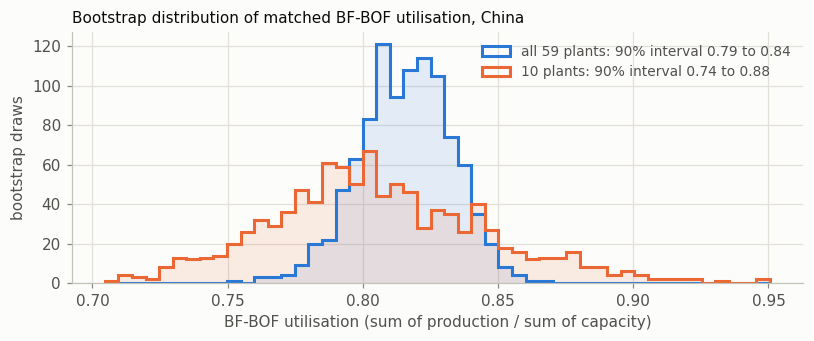

In [14]:
def boot_mean_u(df, n=1000, seed=SEED):
    """n bootstrap values of the matched utilisation (sum of production / sum of capacity), resampling plants."""
    per_plant = df.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
    prod, cap = per_plant["Production_ttpa"].to_numpy(), per_plant[CAP].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(per_plant), size=(n, len(per_plant)))
    return prod[idx].sum(1) / cap[idx].sum(1)

bf_matched = obs_matched[obs_matched["Technology_type"] == "BF-BOF"]
small_ids = np.random.default_rng(SEED).choice(np.sort(bf_matched["Plant ID"].unique()), size=10, replace=False)
bf_small = bf_matched[bf_matched["Plant ID"].isin(small_ids)]

boot_all, boot_small = boot_mean_u(bf_matched), boot_mean_u(bf_small)
ci_all, ci_small = np.percentile(boot_all, [5, 95]), np.percentile(boot_small, [5, 95])
for name, sample, ci in [("all", bf_matched, ci_all), ("10 plants", bf_small, ci_small)]:
    point = sample["Production_ttpa"].sum() / sample[CAP].sum()
    print(f"BF-BOF, {name:9s}: {sample['Plant ID'].nunique():2d} plants, estimate {point:.3f}, "
          f"90% interval [{ci[0]:.3f}, {ci[1]:.3f}], width {ci[1] - ci[0]:.3f}")

# Chart style: validated categorical colours (slots 1-3), recessive grid and axes.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

def style_axes(ax, title, xlabel, ylabel):
    ax.figure.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8, alpha=1); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelcolor=INK2)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel(xlabel, color=INK2); ax.set_ylabel(ylabel, color=INK2)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = np.linspace(min(boot_all.min(), boot_small.min()), max(boot_all.max(), boot_small.max()), 50)
for values, ci, label, color in [(boot_all, ci_all, f"all {bf_matched['Plant ID'].nunique()} plants", SERIES[0]),
                                 (boot_small, ci_small, "10 plants", SERIES[1])]:
    ax.hist(values, bins=bins, color=color, alpha=0.12)
    ax.hist(values, bins=bins, histtype="step", color=color, linewidth=2,
            label=f"{label}: 90% interval {ci[0]:.2f} to {ci[1]:.2f}")
style_axes(ax, "Bootstrap distribution of matched BF-BOF utilisation, China",
           "BF-BOF utilisation (sum of production / sum of capacity)", "bootstrap draws")
ax.legend(frameon=False, fontsize=9, labelcolor=INK2)
plt.tight_layout(); plt.show()

### Q7 [QUANT + QUAL] Small sample, wide interval

(a) Report `ci_all` and `ci_small` and their widths. (b) Why is the second wider? (c) In one sentence, what does "90% interval" mean here? (d) Which kind of uncertainty (A or E) shrinks when you have more plants?

**Your answer (Q7):**

(a) `ci_all` = **[0.788, 0.842]** (59 plants), **width 0.054**; `ci_small` = **[0.743, 0.878]** (10 plants), **width 0.134**, i.e. 2.5 times wider.

(b) With 10 plants each resample is dominated by a few plants, so the average swings much more from one resample to the next. The spread of an average shrinks like 1/√n, and √(59/10) ≈ 2.4 matches the 2.5× ratio.

(c) If the reporting plants are a random sample of China's BF-BOF plants, intervals built this way would contain the true average BF-BOF utilisation in 90% of repeated samples. It says how reliable the method is, not that this particular range has a 90% probability.

(d) The **epistemic** uncertainty about the average shrinks with more plants. The aleatoric plant-to-plant and year-to-year variation does not.

> ### [OPTIONAL] Bayesian version of the same interval
>
> A **credible interval** answers a more direct question: *given the data and what I believed before, where is the true average?* We start from a **prior guess** (mean $\mu_0$, worth $\kappa_0$ observations) and update it with the data (mean $\bar x$, $n$ observations):
>
> posterior mean $=\dfrac{\kappa_0\,\mu_0 + n\,\bar x}{\kappa_0+n}$ (a weighted average: the prior counts as $\kappa_0$ observations).
>
> **Task.** For the **10 plants** of `ci_small`, compute the posterior mean for (i) a **weak** prior ($\mu_0=0.5$, $\kappa_0=0.01$) and (ii) a **wrong** prior ($\mu_0=0.3$, $\kappa_0=5$). The width of a 90% interval is roughly $1.8\times s/\sqrt{n+\kappa_0}$ ($s$ = standard deviation of the 10 values).
> **Question Q7b.** How much does the wrong prior move the answer, and why does this matter when data are scarce?

In [15]:
per_plant_small = bf_small.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
x = per_plant_small["Production_ttpa"] / per_plant_small[CAP]  # the 10 plant utilisations
n10, xbar, s = len(x), x.mean(), x.std(ddof=1)
print(f"10 plants: mean {xbar:.3f}, sd {s:.3f}")
for name, mu0, kappa0 in [("weak prior", 0.5, 0.01), ("wrong prior", 0.3, 5)]:
    post_mean = (kappa0 * mu0 + n10 * xbar) / (kappa0 + n10)
    half = 0.9 * s / np.sqrt(n10 + kappa0)  # 90% width ~ 1.8 s / sqrt(n + kappa0)
    print(f"{name:11s} (mu0={mu0}, kappa0={kappa0}): posterior mean {post_mean:.3f} "
          f"(moves {post_mean - xbar:+.3f}), 90% interval ~[{post_mean - half:.3f}, {post_mean + half:.3f}]")

per_plant_all = bf_matched.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
x_all = per_plant_all["Production_ttpa"] / per_plant_all[CAP]
print(f"Same wrong prior with all {len(x_all)} plants: moves the mean by "
      f"{(5 * 0.3 + len(x_all) * x_all.mean()) / (5 + len(x_all)) - x_all.mean():+.3f}")

10 plants: mean 0.837, sd 0.135
weak prior  (mu0=0.5, kappa0=0.01): posterior mean 0.837 (moves -0.000), 90% interval ~[0.798, 0.875]
wrong prior (mu0=0.3, kappa0=5): posterior mean 0.658 (moves -0.179), 90% interval ~[0.627, 0.689]
Same wrong prior with all 59 plants: moves the mean by -0.041


**Your answer (Q7b (optional)):**

The 10 plants have mean utilisation 0.837 and standard deviation 0.135.
* **Weak prior:** changes nothing (posterior 0.837, interval ≈ [0.80, 0.88]).
* **Wrong prior** (μ0 = 0.3, worth 5 plants): pulls the estimate down by 0.18 to **0.658**. It also narrows the interval to ≈ [0.63, 0.69], which does not even contain the data mean: a precise but wrong answer.

With 10 observations the prior carries a third of the weight (5 out of 15). With all 59 plants, the same prior would move the estimate by only 0.04. When data are scarce, the prior drives the result, so it has to be justified (e.g. by the official-implied ~0.8) and its influence reported.

## B4. Simulation: a range for emissions

**Idea (Monte Carlo).** Instead of one value per input, use a *plausible range*, then **repeat the whole calculation many times**, each time with different plausible values. The cloud of results shows the uncertainty of the output.

Two uncertain inputs:

| Input | Plausible range | How to draw |
|---|---|---|
| **Utilisation** per technology | the bootstrap values of B3 | one bootstrap value per draw and technology (all technologies pooled if a technology has fewer than 5 plants) |
| **Emission factor** per technology | multiplier on your Part A factor, **assumed illustrative values** below | triangular distribution (low, mode = 1, high): `rng.triangular(low, 1, high, size=n)` |

| Technology | low | mode | high |
|---|---|---|---|
| BF-BOF | 0.85 | 1 | 1.20 |
| EAF | 0.65 | 1 | 2.00 |
| Other | 0.65 | 1 | 1.40 |

**Goal.** Create `ef_mult_ranges` (dict) and a function `simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0)` returning a dict with
* `national`: array of `n` national emissions (**MtCO2**) for `year`;
* `national_prod`: array of `n` national productions (**Mt**);
* `by_company`: DataFrame (`n` rows, one column per company, MtCO2).

> **Hint.**
> 1. Take the rows of `china_operational` for `year`. For every plant you need: capacity (missing = 0), technology, your Part A emission factor, company.
> 2. Draw a matrix `u` (n x 3) of utilisations and a matrix `mult` (n x 3) of multipliers (columns = BF-BOF, EAF, Other). If `vary_util=False`, use the pooled matched utilisation of each technology instead (sum of production / sum of capacity over all years); if `vary_ef=False`, use multipliers equal to 1.
> 3. Choose each plant's column by its technology: `u[:, tech_index_of_plant]` gives an (n x plants) matrix. Then production = capacity x utilisation (x `util_mult`), emissions = production x 1,000 x factor x multiplier / 1e6.
> 4. `bf_cap_mult` multiplies the capacity of BF-BOF plants (used for scenarios later).
> 5. Company totals: `pd.DataFrame(em_matrix, columns=company_of_each_plant).T.groupby(level=0).sum().T`.

In [16]:
ef_mult_ranges = {"BF-BOF": (0.85, 1, 1.20), "EAF": (0.65, 1, 2.00), "Other": (0.65, 1, 1.40)}

# Utilisation inputs per technology: bootstrap values and the pooled matched value (all years).
# A technology with fewer than 5 matched plants borrows the all-technology (pooled) sample.
matched_plants_by_tech = obs_matched.groupby("Technology_type")["Plant ID"].nunique().reindex(TECHS, fill_value=0)
boot_u, pooled_u = {}, {}
for tech in TECHS:
    sample = obs_matched[obs_matched["Technology_type"] == tech] if matched_plants_by_tech[tech] >= 5 else obs_matched
    boot_u[tech] = boot_mean_u(sample)
    pooled_u[tech] = sample["Production_ttpa"].sum() / sample[CAP].sum()
display(pd.DataFrame({"matched plants": matched_plants_by_tech, "pooled utilisation": pd.Series(pooled_u),
                      "bootstrap 5%": {t: np.percentile(v, 5) for t, v in boot_u.items()},
                      "bootstrap 95%": {t: np.percentile(v, 95) for t, v in boot_u.items()}}))

def simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0):
    """Monte Carlo of China's emissions in `year`: n draws of utilisation and emission-factor multipliers."""
    rng = np.random.default_rng(seed)
    plants = china_operational[china_operational["Year"] == year]
    tech = plants["Technology_type"].map(TECHS.index).to_numpy()  # column of each plant: 0 BF-BOF, 1 EAF, 2 Other
    cap = plants[CAP].fillna(0).to_numpy() * np.where(tech == 0, bf_cap_mult, 1.0)
    ef = plants["Emission_factor_tCO2_per_t"].to_numpy()

    if vary_util:
        u = np.column_stack([rng.choice(boot_u[t], size=n) for t in TECHS])
    else:
        u = np.tile([pooled_u[t] for t in TECHS], (n, 1))
    if vary_ef:
        mult = np.column_stack([rng.triangular(*ef_mult_ranges[t], size=n) for t in TECHS])
    else:
        mult = np.ones((n, len(TECHS)))

    prod = cap * u[:, tech] * util_mult            # n x plants, ttpa
    em = prod * 1_000 * ef * mult[:, tech] / 1e6   # n x plants, MtCO2
    by_company = pd.DataFrame(em, columns=plants["Company"].to_numpy()).T.groupby(level=0).sum().T
    return {"national": em.sum(1), "national_prod": prod.sum(1) / 1_000, "by_company": by_company}

def interval(draws):
    """Median, 90% interval and relative half-width of a set of draws."""
    p5, med, p95 = np.percentile(draws, [5, 50, 95])
    return pd.Series({"median": med, "p5": p5, "p95": p95, "rel_half_width": (p95 - p5) / (2 * med)})

test = simulate(1000)
print("national:", test["national"].shape, "| national_prod:", test["national_prod"].shape,
      "| by_company:", test["by_company"].shape)

,matched plants,pooled utilisation,bootstrap 5%,bootstrap 95%
BF-BOF,59,0.82,0.79,0.84
EAF,7,0.71,0.52,0.79
Other,0,0.81,0.78,0.84


national: (1000,) | national_prod: (1000,) | by_company: (1000, 339)


### Q8 [QUANT + QUAL] Read the result

(a) For **2030**, report the **median** and the **90% interval** (5th to 95th percentile) of national emissions, and the **relative half-width** = (upper - lower) / (2 x median). (b) Compare the median with your **Part A value for 2030** (sum of `company_emissions` for 2030, in Mt). Which one is closer to the simulation, and why do they differ so much (hint: B1)?

In [17]:
sim_2030 = simulate(1000, year=2030)
q8 = interval(sim_2030["national"])
part_a_2030 = company_emissions.loc[company_emissions["Year"] == 2030, "estimated_emissions_tCO2"].sum() / 1e6
print(f"2030 national emissions: median {q8['median']:,.0f} MtCO2, 90% interval [{q8['p5']:,.0f}, {q8['p95']:,.0f}], "
      f"relative half-width {q8['rel_half_width']:.1%}")
print(f"Part A value for 2030: {part_a_2030:,.0f} MtCO2 -> the simulation median is {q8['median'] / part_a_2030:.1f}x larger")
print(f"Implied 2030 production: simulation median {np.median(sim_2030['national_prod']):,.0f} Mt, Part A "
      f"{china_operational.loc[china_operational['Year'] == 2030, 'Estimated_production_ttpa'].sum() / 1e3:,.0f} Mt "
      f"(official output: 1,020 Mt in 2023)")

2030 national emissions: median 1,928 MtCO2, 90% interval [1,720, 2,186], relative half-width 12.1%
Part A value for 2030: 151 MtCO2 -> the simulation median is 12.8x larger
Implied 2030 production: simulation median 1,024 Mt, Part A 77 Mt (official output: 1,020 Mt in 2023)


**Your answer (Q8):**

(a) 2030 national emissions: **median 1,928 MtCO2**, 90% interval **[1,720, 2,186] MtCO2**, relative half-width **12.1%**.

(b) Part A gives **151 MtCO2** for 2030, so the simulation median is **12.8 times larger**. The simulation is the realistic one: its implied production (median 1,024 Mt) is in line with official output (1,020 Mt in 2023), while Part A implies only 77 Mt.

They differ so much because of B1. Part A divides the production of the few plants that report (9.5% coverage in 2023; only 11 plants in 2024) by the capacity of all plants, so its 7% BF-BOF "utilisation" measures data coverage. The simulation uses the matched utilisation (about 0.8), consistent with the official-implied rate.

### Q9 [QUANT + QUAL] Which input matters most?

Run `simulate` twice: once varying **only the utilisation** (`vary_ef=False`) and once varying **only the emission factor** (`vary_util=False`). For each, give the relative half-width for 2030. Which input creates more of the uncertainty? Could **more data** reduce it?

In [18]:
q9 = pd.DataFrame({
    "both vary": interval(sim_2030["national"]),
    "utilisation only (vary_ef=False)": interval(simulate(1000, 2030, vary_ef=False)["national"]),
    "emission factor only (vary_util=False)": interval(simulate(1000, 2030, vary_util=False)["national"]),
}).T
display(q9)
print("Relative half-width: " + ", ".join(f"{k} {v:.1%}" for k, v in q9["rel_half_width"].items()))

,median,p5,p95,rel_half_width
both vary,"1,927.54","1,719.67","2,185.62",0.12
utilisation only (vary_ef=False),"1,904.73","1,846.47","1,965.43",0.03
emission factor only (vary_util=False),"1,945.43","1,737.94","2,168.90",0.11


Relative half-width: both vary 12.1%, utilisation only (vary_ef=False) 3.1%, emission factor only (vary_util=False) 11.1%


**Your answer (Q9):**

* **Utilisation only:** relative half-width **3.1%** ([1,846, 1,965] MtCO2).
* **Emission factor only:** **11.1%** ([1,738, 2,169] MtCO2).
* **Both together:** 12.1%.

The **emission factor** creates most of the uncertainty, about 3.5 times more than utilisation, which is pinned down by 59 BF-BOF plants.

More data could reduce it, because the factor uncertainty is epistemic. Measured plant-level emissions (company reports, the verified data China's national carbon market now collects from steel plants) would narrow it. More plants would only shrink the already small utilisation term, and year-to-year (aleatoric) swings are not in the model at all. The factor ranges are assumed illustrative values, so this ranking is itself an assumption.

### Q10 [QUANT + QUAL] Companies: can you say who is number one?

Using `by_company` of your 2030 run: (a) for the **top 3 companies by median**, give the median and the 90% interval; (b) compute the probability that the #1 company emits **more than** the #2 (fraction of simulations); (c) what would you write in a report instead of "Company X is the largest emitter"?

In [19]:
by_company = sim_2030["by_company"]
top3 = by_company.median().sort_values(ascending=False).index[:3]
q10 = pd.DataFrame({c: interval(by_company[c]) for c in top3}).T.drop(columns="rel_half_width")
with pd.option_context("display.max_colwidth", 120):
    display(q10)
p_1_gt_2 = (by_company[top3[0]] > by_company[top3[1]]).mean()
ratio = by_company[top3[0]] / by_company[top3[1]]
print(f"P(#1 > #2) = {p_1_gt_2:.3f}; ratio #1 / #2 ranges from {ratio.min():.4f} to {ratio.max():.4f} across draws")
print("Capacity of the top 3 by technology in 2030 (ttpa):")
with pd.option_context("display.max_colwidth", 120):
    display(china_operational[(china_operational["Year"] == 2030) & china_operational["Company"].isin(top3)]
            .pivot_table(index="Company", columns="Technology_type", values=CAP, aggfunc="sum", fill_value=0))

,median,p5,p95
Angang Steel Co Ltd [100.0%],56.24,50.03,63.93
Baoshan Iron & Steel Co Ltd [100.0%],53.54,47.63,60.86
Beijing Shougang Co Ltd [100.0%],38.67,34.40,43.96


P(#1 > #2) = 1.000; ratio #1 / #2 ranges from 1.0503 to 1.0503 across draws
Capacity of the top 3 by technology in 2030 (ttpa):


Technology_type,BF-BOF
Company,
Angang Steel Co Ltd [100.0%],"33,700.00"
Baoshan Iron & Steel Co Ltd [100.0%],"35,707.00"
Beijing Shougang Co Ltd [100.0%],"23,300.00"


**Your answer (Q10):**

(a) Top 3 by median in 2030 (MtCO2, 90% interval):

| Company | Median | 90% interval |
|---|---|---|
| Angang Steel Co Ltd | 56.2 | [50.0, 63.9] |
| Baoshan Iron & Steel Co Ltd | 53.5 | [47.6, 60.9] |
| Beijing Shougang Co Ltd | 38.7 | [34.4, 44.0] |

(b) **P(#1 > #2) = 1.00**: Angang is ahead in all 1,000 draws, even though the two intervals overlap almost completely.

(c) The 100% is a model artefact, not certainty.
* Both companies are pure BF-BOF, and each draw gives every BF-BOF plant the same utilisation and factor multiplier. The ratio between them is therefore exactly 1.050 in every draw, and the order is fixed by capacity × factor.
* What could really reorder them is not simulated: company-specific utilisation and factors, which capacity truly operates (Q1), and ownership. Baoshan belongs to the Baowu group, which would rank first at group level (Q2).

In a report I would write: *"Angang Steel and Baoshan Iron & Steel are estimated to be the two largest emitters in 2030, each emitting roughly 48 to 64 MtCO2. The 5% gap between them is smaller than the uncertainty in company-level data, so their order is not established."*

## B5. Is the interval honest? Test it

A 90% interval should contain the true value in about 90% of cases. We have one case where the truth is known: **official 2023 production**.

### Q11 [QUANT + QUAL] Does the official value fall inside?

Run `simulate(1000, year=2023)` and look at `national_prod` (Mt). (a) Give its 90% interval and say whether the official 2023 value (1,020 Mt) falls inside. (b) If not, what does this tell you about the interval, **even though it was computed correctly**? (c) What would you do about it?

In [20]:
sim_2023 = simulate(1000, year=2023)
prod_2023 = interval(sim_2023["national_prod"])
official_2023_mt = official_kt[2023] / 1_000
print(f"2023 production: median {prod_2023['median']:,.0f} Mt, 90% interval [{prod_2023['p5']:,.0f}, {prod_2023['p95']:,.0f}] Mt; "
      f"official {official_2023_mt:,.0f} Mt inside: {prod_2023['p5'] <= official_2023_mt <= prod_2023['p95']}")

# One known year is a weak test: repeat it for every year with an official figure.
calibration = pd.DataFrame({y: interval(simulate(1000, year=y)["national_prod"]) for y in official_kt}).T
calibration["official"] = pd.Series(official_kt) / 1_000
calibration["inside"] = calibration["official"].between(calibration["p5"], calibration["p95"])
display(calibration.drop(columns="rel_half_width"))
print(f"Official value inside the 90% interval in {calibration['inside'].sum()} of {len(calibration)} years. "
      f"2023 capacity counted: {china_capacity[2023] / 1e3:,.0f} Mt, of which "
      f"{china_operational.loc[china_operational['Year'] == 2023, 'Non-operating capacity (ttpa)'].sum() / 1e3:,.0f} Mt "
      f"with a non-operating status.")

2023 production: median 1,032 Mt, 90% interval [995, 1,067] Mt; official 1,020 Mt inside: True


,median,p5,p95,official,inside
2020,"1,076.08","1,038.43","1,111.27","1,065.00",True
2021,"1,072.92","1,035.04","1,108.40","1,035.00",False
2022,"1,060.93","1,023.33","1,096.10","1,015.00",False
2023,"1,032.34",995.05,"1,066.77","1,020.00",True


Official value inside the 90% interval in 2 of 4 years. 2023 capacity counted: 1,288 Mt, of which 201 Mt with a non-operating status.


**Your answer (Q11):**

(a) Simulated 2023 production: **median 1,032 Mt, 90% interval [995, 1,067] Mt**. The official 1,020 Mt **falls inside**.

(b) One hit says little about a "90%" claim. Repeating the test for every year with an official figure, the value is inside in only **2 of 4 years** (2021: 1,035 Mt vs [1,035, 1,108], just outside; 2022: 1,015 Mt vs [1,023, 1,096]). The interval is computed correctly but is **too narrow (over-confident)**: it only contains what we chose to vary, i.e. the sampling uncertainty of the *average* utilisation (production does not depend on the emission factor). It leaves out:
* year-to-year swings in utilisation;
* which capacity really operates (201 of the 1,288 Mt counted in 2023 has a non-operating status);
* plants missing from the tracker;
* the selection bias of reporting plants.

The 2023 hit is also in-sample (2023 plants are in the bootstrap) and partly comes from errors that offset each other.

(c) I would:
* add the missing sources (year-by-year utilisation, uncertainty on operating capacity and on small-plant coverage);
* test out of sample (estimate without one year, then check that year);
* calibrate the width so that about 90% of known official values fall inside, or at least present the range as "conditional on the model".

## B6. Scenarios

A **scenario** is a "what if" story. We do **not** attach a probability to it; we run each one through the same simulation and compare.

| Scenario | Story | How |
|---|---|---|
| **S0** | no change | as is |
| **S1** | **30% of BF-BOF capacity is retired** (by 2027, still true in 2030) | `bf_cap_mult=0.7` |
| **S2** | **steel demand drops**: utilisation 10% lower | `util_mult=0.9` |

### Q12 [QUANT + QUAL] Scenario gap vs interval width

(a) Run the three scenarios for 2030 and give the **median and 90% interval** of each. (b) Compare the **gap between** scenario medians with the **width of the interval** within a scenario. Which is bigger? (c) Why would it be misleading to average the three scenarios into one probability-weighted number?

,median,p5,p95,rel_half_width,interval width,gap to S0 median
S0 no change,"1,927.54","1,719.67","2,185.62",0.12,465.96,0.00
S1 30% of BF-BOF retired,"1,366.69","1,216.65","1,544.27",0.12,327.62,-560.84
S2 utilisation -10%,"1,734.78","1,547.70","1,967.06",0.12,419.36,-192.75


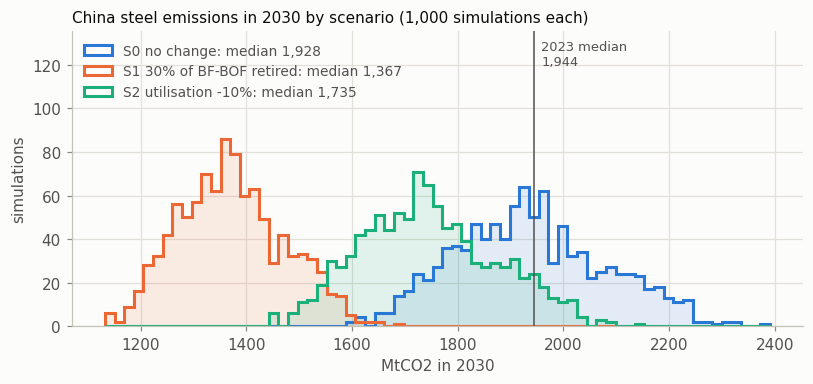

In [21]:
scenarios = {"S0 no change": {}, "S1 30% of BF-BOF retired": {"bf_cap_mult": 0.7}, "S2 utilisation -10%": {"util_mult": 0.9}}
scenario_draws = {name: simulate(1000, year=2030, **kwargs)["national"] for name, kwargs in scenarios.items()}
q12 = pd.DataFrame({name: interval(d) for name, d in scenario_draws.items()}).T
q12["interval width"] = q12["p95"] - q12["p5"]
q12["gap to S0 median"] = q12["median"] - q12.loc["S0 no change", "median"]
display(q12)

threshold_2023 = np.median(sim_2023["national"])  # 2023 median emissions, also the Q13 threshold
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(min(d.min() for d in scenario_draws.values()), max(d.max() for d in scenario_draws.values()), 70)
for (name, draws), color in zip(scenario_draws.items(), SERIES):
    ax.hist(draws, bins=bins, color=color, alpha=0.12)
    ax.hist(draws, bins=bins, histtype="step", color=color, linewidth=2, label=f"{name}: median {np.median(draws):,.0f}")
ax.set_ylim(0, ax.get_ylim()[1] * 1.5)  # headroom for the legend
ax.axvline(threshold_2023, color=INK2, linewidth=1)
ax.annotate(f"2023 median\n{threshold_2023:,.0f}", xy=(threshold_2023, ax.get_ylim()[1] * 0.97), xytext=(5, 0),
            textcoords="offset points", va="top", fontsize=8.5, color=INK2)
style_axes(ax, "China steel emissions in 2030 by scenario (1,000 simulations each)",
           "MtCO2 in 2030", "simulations")
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc="upper left")
plt.tight_layout(); plt.show()

**Your answer (Q12):**

(a) 2030 national emissions (MtCO2):

| Scenario | Median | 90% interval |
|---|---|---|
| S0 (no change) | 1,928 | [1,720, 2,186] |
| S1 (30% of BF-BOF retired) | 1,367 | [1,217, 1,544] |
| S2 (utilisation −10%) | 1,735 | [1,548, 1,967] |

(b) Retiring 30% of BF-BOF capacity moves the median by **−561 MtCO2**, more than the full width of any 90% interval (328 to 466 Mt). The demand scenario moves it by **−193 MtCO2**, less than the width. So the policy choice behind S1 matters more than all the statistical uncertainty we simulated. S2's shift is smaller than the noise, although, with the same random draws, S2 is below S0 in every single draw.

(c) Scenarios carry no probabilities, so any weights would be invented. A weighted average (about 1,680 MtCO2 with equal weights) describes a world that none of the scenarios represents. Averaging also hides the gap between paths that depend on decisions (retiring furnaces is a policy and engagement choice), which a risk committee should see and stress-test one at a time, and it understates the tails.

## B7. Communicate

Words used by the IPCC for probabilities: **virtually certain** 99-100%, **very likely** 90-100%, **likely** 66-100%, **about as likely as not** 33-66%, **unlikely** 10-33%, **very unlikely** 1-10%, **exceptionally unlikely** 0-1%.

### Q13 [QUANT + QUAL] A probability, a word, and a note

(a) For each scenario, compute the probability that **2030 emissions exceed the 2023 median** (from your `simulate(..., year=2023)`) and give the matching word. (b) Write a note of **about 80 words** for a bank's risk committee about China's steel emissions in 2030. Include: the **median and 90% interval** (baseline), **one sentence on the scenarios**, the **biggest source of uncertainty**, **one limitation** of the model and **one recommended action**. Plain language, no jargon.

> **Hint.** `(draws > threshold).mean()`.

In [22]:
def ipcc_word(p):
    """Most specific IPCC likelihood term for a probability p."""
    for bound, word in [(0.99, "virtually certain"), (0.90, "very likely"), (0.66, "likely"),
                        (0.33, "about as likely as not"), (0.10, "unlikely"), (0.01, "very unlikely")]:
        if p >= bound:
            return word
    return "exceptionally unlikely"

q13 = pd.DataFrame({"P(2030 > 2023 median)": {name: (d > threshold_2023).mean() for name, d in scenario_draws.items()}})
q13["IPCC word"] = q13["P(2030 > 2023 median)"].map(ipcc_word)
print(f"2023 median national emissions: {threshold_2023:,.0f} MtCO2")
display(q13)

2023 median national emissions: 1,944 MtCO2


,P(2030 > 2023 median),IPCC word
S0 no change,0.45,about as likely as not
S1 30% of BF-BOF retired,0.00,exceptionally unlikely
S2 utilisation -10%,0.07,very unlikely


**Your answer (Q13):**

(a) The simulated 2023 median is 1,944 MtCO2. Probability that 2030 emissions exceed it:

| Scenario | Probability | IPCC term |
|---|---|---|
| S0 | 0.45 | about as likely as not |
| S1 | 0.00 | exceptionally unlikely |
| S2 | 0.07 | very unlikely |

(b) Note to the risk committee:

> If nothing changes, China's steel plants would emit about 1.9 billion tonnes of CO2 in 2030 (90% range: 1.7 to 2.2 billion), about as likely as not above 2023 levels. Retiring 30% of blast-furnace capacity would cut this to about 1.4 billion; 10% weaker demand, to about 1.7 billion. The biggest uncertainty is the CO2 emitted per tonne of steel. Limitation: plant production data cover only about 10% of output. Action: require borrowers to report plant-level production and emissions.